In [2]:
# Cell 1 — imports
from pathlib import Path

import numpy as np
from PIL import Image
from scipy import ndimage
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point
import matplotlib.pyplot as plt

DATA_RAW = Path("../data/raw/NuwaraEliya")
DATA_PROCESSED = Path("../data/processed")
DATA_RAW.mkdir(parents=True, exist_ok=True)


In [3]:
import fitz
from pathlib import Path

def pdf_to_png(pdf_path, out_prefix, dpi=300):
    pdf_path = Path(pdf_path)

    if not pdf_path.exists():
        raise FileNotFoundError(f"PDF not found: {pdf_path}")

    doc = fitz.open(pdf_path)

    page = doc[0]

    zoom = dpi / 72
    matrix = fitz.Matrix(zoom, zoom)

    pix = page.get_pixmap(matrix=matrix, alpha=False)

    png_path = Path(f"{out_prefix}-1.png")
    pix.save(str(png_path))

    doc.close()

    return png_path

In [4]:
MAP_NAME= "NuwaraEliya"

In [5]:
pdf_path = DATA_RAW / f"{MAP_NAME.upper()}.pdf"

png_path = pdf_to_png(
    pdf_path,
    str(DATA_RAW / MAP_NAME)
)

im = Image.open(png_path).convert("RGB")
arr = np.array(im)

In [6]:
def find_frame_borders_nuwaraeliya(arr):
    h, w, _ = arr.shape

    # =========================================================
    # LEFT BORDER
    # Search only near the expected left edge of the map
    # =========================================================
    x0, x1 = int(w * 0.02), int(w * 0.12)

    region = arr[
        int(h * 0.20):int(h * 0.75),
        x0:x1,
        :
    ]

    gray = region.sum(axis=2)
    frac_dark = (gray < 300).mean(axis=0)

    candidates = np.where(frac_dark > 0.45)[0]

    if len(candidates) == 0:
        raise ValueError("Could not detect left map border.")

    left = candidates[0] + x0


    # =========================================================
    # RIGHT BORDER
    # Nuwara Eliya map ends before the legend/table area
    # =========================================================
    x0, x1 = int(w * 0.58), int(w * 0.70)

    region = arr[
        int(h * 0.20):int(h * 0.75),
        x0:x1,
        :
    ]

    gray = region.sum(axis=2)
    frac_dark = (gray < 300).mean(axis=0)

    candidates = np.where(frac_dark > 0.45)[0]

    if len(candidates) == 0:
        raise ValueError("Could not detect right map border.")

    right = candidates[-1] + x0


    # =========================================================
    # TOP BORDER
    # =========================================================
    y0, y1 = int(h * 0.04), int(h * 0.18)

    region = arr[
        y0:y1,
        left:right,
        :
    ]

    gray = region.sum(axis=2)
    frac_dark = (gray < 300).mean(axis=1)

    candidates = np.where(frac_dark > 0.45)[0]

    if len(candidates) == 0:
        raise ValueError("Could not detect top map border.")

    top = candidates[0] + y0


    # =========================================================
    # BOTTOM BORDER
    # =========================================================
    y0, y1 = int(h * 0.70), int(h * 0.93)

    region = arr[
        y0:y1,
        left:right,
        :
    ]

    gray = region.sum(axis=2)
    frac_dark = (gray < 300).mean(axis=1)

    candidates = np.where(frac_dark > 0.45)[0]

    if len(candidates) == 0:
        raise ValueError("Could not detect bottom map border.")

    bottom = candidates[-1] + y0

    return left, right, top, bottom


X_MIN, X_MAX, Y_MIN, Y_MAX = find_frame_borders_nuwaraeliya(arr)

print(
    f"Nuwara Eliya frame: "
    f"x=[{X_MIN}, {X_MAX}], "
    f"y=[{Y_MIN}, {Y_MAX}]"
)

print("Frame width :", X_MAX - X_MIN)
print("Frame height:", Y_MAX - Y_MIN)

Nuwara Eliya frame: x=[170, 3348], y=[140, 3238]
Frame width : 3178
Frame height: 3098


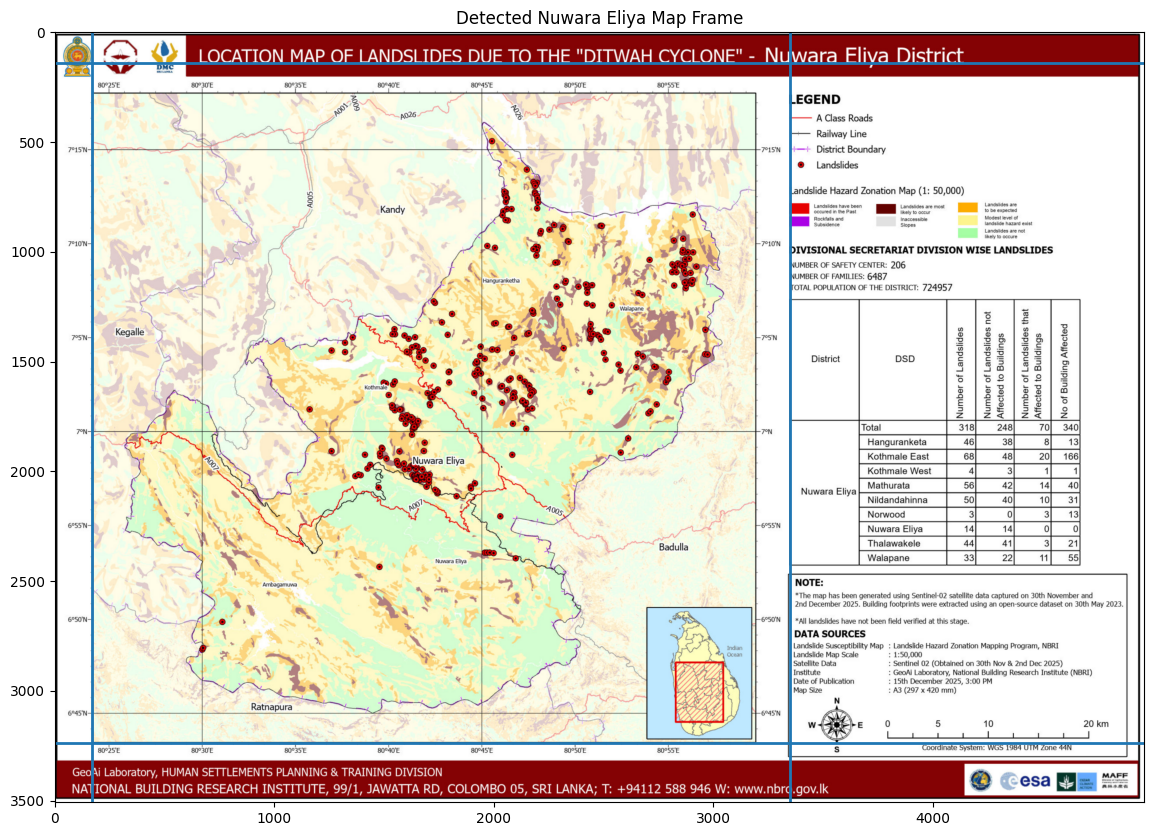

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 10))

plt.imshow(arr)

plt.axvline(X_MIN, linewidth=2)
plt.axvline(X_MAX, linewidth=2)

plt.axhline(Y_MIN, linewidth=2)
plt.axhline(Y_MAX, linewidth=2)

plt.xlim(0, arr.shape[1])
plt.ylim(arr.shape[0], 0)

plt.title("Detected Nuwara Eliya Map Frame")
plt.show()

In [8]:
def zoom_crop(arr, x0, y0, x1, y1, scale=3, save_path="zoom_check.png"):
    crop = Image.fromarray(arr[y0:y1, x0:x1])
    crop = crop.resize(
        (crop.width * scale, crop.height * scale),
        Image.LANCZOS
    )
    crop.save(save_path)
    return save_path

In [9]:
# ============================================================
# Nuwara Eliya — Find Exact Graticule/Gridline Pixel Positions
# ============================================================

def find_vertical_gridline_nuwaraeliya(
    arr,
    x_search_start,
    x_search_end,
    y0,
    y1,
    dark_threshold=400,
    min_fraction=0.45
):
    """
    Find the exact X pixel position of a vertical longitude
    gridline inside a narrow search window.

    IMPORTANT:
    x_search_start and x_search_end should surround ONE
    expected longitude gridline only.
    """

    # Keep search inside detected map frame
    x_search_start = max(x_search_start, X_MIN)
    x_search_end   = min(x_search_end, X_MAX)

    y0 = max(y0, Y_MIN)
    y1 = min(y1, Y_MAX)

    strip = arr[
        y0:y1,
        x_search_start:x_search_end,
        :
    ]

    gray = strip.sum(axis=2)

    # Fraction of dark pixels for each X position
    frac_dark = (gray < dark_threshold).mean(axis=0)

    candidates = np.where(
        frac_dark > min_fraction
    )[0]

    if len(candidates) == 0:
        return None

    # Use strongest vertical dark response
    strongest = candidates[
        np.argmax(frac_dark[candidates])
    ]

    return int(strongest + x_search_start)


def find_horizontal_gridline_nuwaraeliya(
    arr,
    y_search_start,
    y_search_end,
    x0,
    x1,
    dark_threshold=400,
    min_fraction=0.45
):
    """
    Find the exact Y pixel position of a horizontal latitude
    gridline inside a narrow search window.

    IMPORTANT:
    y_search_start and y_search_end should surround ONE
    expected latitude gridline only.
    """

    # Keep search inside detected map frame
    y_search_start = max(y_search_start, Y_MIN)
    y_search_end   = min(y_search_end, Y_MAX)

    x0 = max(x0, X_MIN)
    x1 = min(x1, X_MAX)

    strip = arr[
        y_search_start:y_search_end,
        x0:x1,
        :
    ]

    gray = strip.sum(axis=2)

    # Fraction of dark pixels for each Y position
    frac_dark = (gray < dark_threshold).mean(axis=1)

    candidates = np.where(
        frac_dark > min_fraction
    )[0]

    if len(candidates) == 0:
        return None

    # Use strongest horizontal dark response
    strongest = candidates[
        np.argmax(frac_dark[candidates])
    ]

    return int(strongest + y_search_start)

Possible longitude X pixels:
[ 349  670 1101 1364 1651 1944 2290 2699 3191]

Possible latitude Y pixels:
[ 279  535  820 1129 1379 1820 2104 2623 3103]


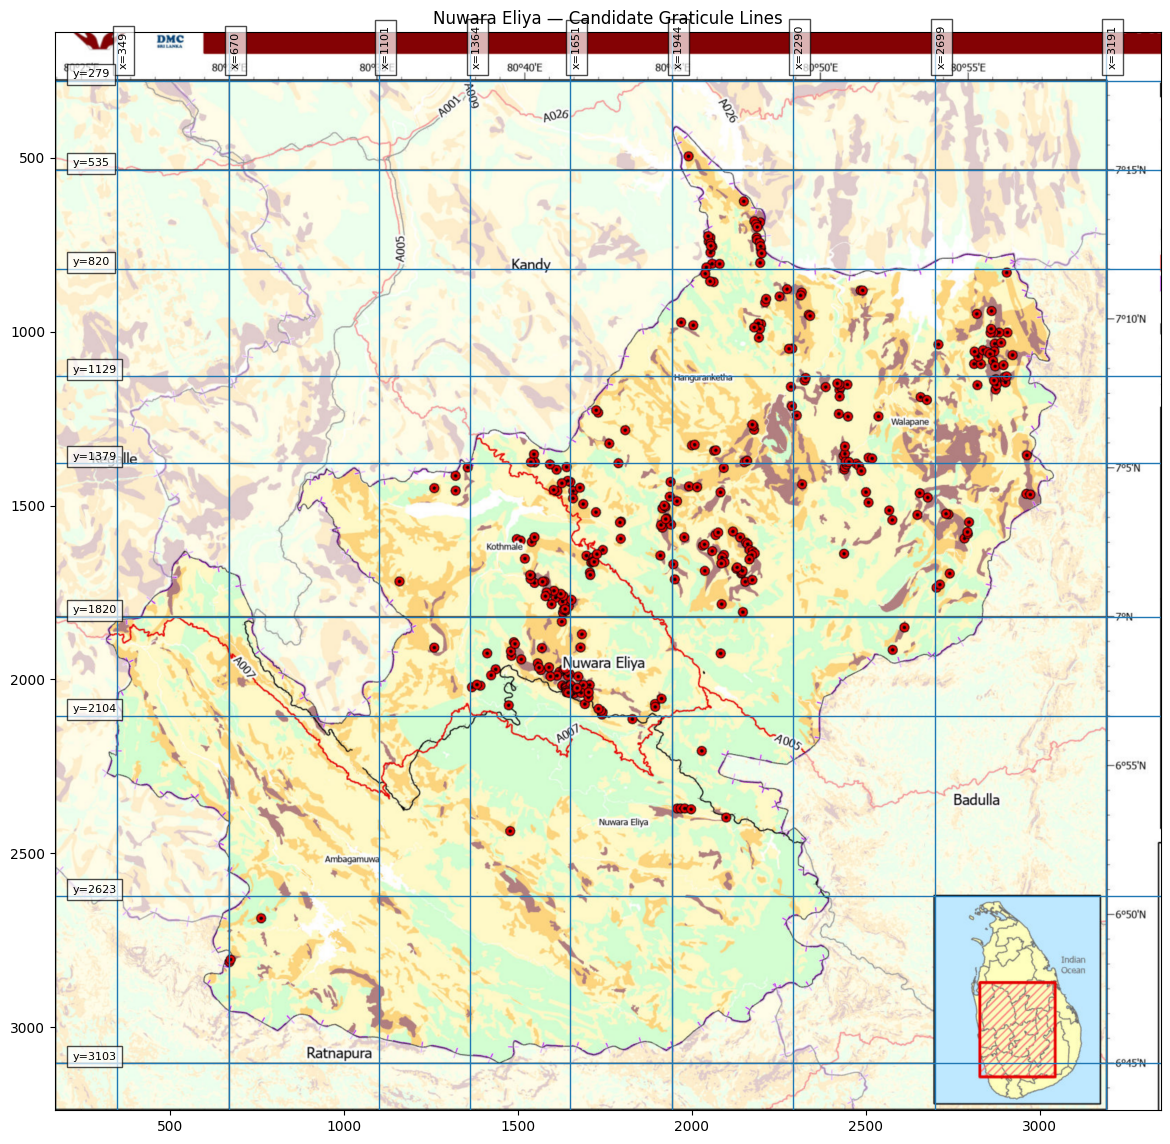

In [10]:
# ============================================================
# NUWARA ELIYA — IDENTIFY GRATICULE PIXEL POSITIONS
# Known frame:
# x = [170, 3348]
# y = [140, 3238]
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

X_MIN, X_MAX = 170, 3348
Y_MIN, Y_MAX = 140, 3238

# Avoid outer black frame
margin = 40

x0 = X_MIN + margin
x1 = X_MAX - margin
y0 = Y_MIN + margin
y1 = Y_MAX - margin

crop = arr[y0:y1, x0:x1, :]

# Convert to grayscale
gray = crop.mean(axis=2)

# Detect dark pixels
dark = gray < 150

# Strength of vertical/horizontal dark lines
vertical_score = dark.mean(axis=0)
horizontal_score = dark.mean(axis=1)

# ------------------------------------------------------------
# Find candidate longitude lines
# ------------------------------------------------------------

v_peaks, v_props = find_peaks(
    vertical_score,
    distance=250,
    prominence=0.01
)

# ------------------------------------------------------------
# Find candidate latitude lines
# ------------------------------------------------------------

h_peaks, h_props = find_peaks(
    horizontal_score,
    distance=250,
    prominence=0.01
)

# Convert back to full image coordinates
vertical_px = v_peaks + x0
horizontal_px = h_peaks + y0

print("Possible longitude X pixels:")
print(vertical_px)

print("\nPossible latitude Y pixels:")
print(horizontal_px)


# ------------------------------------------------------------
# VISUAL CHECK
# ------------------------------------------------------------

plt.figure(figsize=(16, 14))

plt.imshow(arr)

# Vertical candidates
for x in vertical_px:
    plt.axvline(x, linewidth=1)

    plt.text(
        x + 5,
        Y_MIN + 100,
        f"x={x}",
        rotation=90,
        fontsize=8,
        bbox=dict(facecolor="white", alpha=0.7)
    )

# Horizontal candidates
for y in horizontal_px:
    plt.axhline(y, linewidth=1)

    plt.text(
        X_MIN + 50,
        y - 10,
        f"y={y}",
        fontsize=8,
        bbox=dict(facecolor="white", alpha=0.7)
    )

plt.xlim(X_MIN, X_MAX)
plt.ylim(Y_MAX, Y_MIN)

plt.title("Nuwara Eliya — Candidate Graticule Lines")

plt.show()

In [11]:
# ============================================================
# NUWARA ELIYA — PIXEL TO GEOGRAPHIC COORDINATE CALIBRATION
# ============================================================

CALIBRATION = {
    # Replace XXXX with the VISUALLY CONFIRMED pixel positions

    "lon_a_deg": 80.50,     # 80°30'E
    "lon_a_px": 670,

    "lon_b_deg": 80.833333, # 80°50'E
    "lon_b_px": 2290,

    "lat_a_deg": 7.00,      # 7°00'N
    "lat_a_px": 1820,

    "lat_b_deg": 6.833333,  # 6°50'N
    "lat_b_px": 2623
}

# ------------------------------------------------------------
# Calculate pixel scale
# ------------------------------------------------------------

px_per_deg_lon = (
    CALIBRATION["lon_b_px"] - CALIBRATION["lon_a_px"]
) / (
    CALIBRATION["lon_b_deg"] - CALIBRATION["lon_a_deg"]
)

px_per_deg_lat = (
    CALIBRATION["lat_b_px"] - CALIBRATION["lat_a_px"]
) / (
    CALIBRATION["lat_b_deg"] - CALIBRATION["lat_a_deg"]
)


# ------------------------------------------------------------
# Convert image pixel coordinates to longitude / latitude
# ------------------------------------------------------------

def px_to_lonlat(x_full, y_full):

    lon = (
        CALIBRATION["lon_a_deg"]
        + (x_full - CALIBRATION["lon_a_px"]) / px_per_deg_lon
    )

    lat = (
        CALIBRATION["lat_a_deg"]
        + (y_full - CALIBRATION["lat_a_px"]) / px_per_deg_lat
    )

    return lon, lat


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

print("Pixels per degree longitude:", px_per_deg_lon)
print("Pixels per degree latitude :", px_per_deg_lat)

print(
    "Top-left corner:",
    px_to_lonlat(X_MIN, Y_MIN)
)

print(
    "Bottom-right corner:",
    px_to_lonlat(X_MAX, Y_MAX)
)

Pixels per degree longitude: 4860.004860004917
Pixels per degree latitude : -4817.990364019262
Top-left corner: (80.39711944444444, 7.348693100871731)
Bottom-right corner: (81.05102825555555, 6.705686418430884)


In [12]:
def sample_dot_color(arr, x0, y0, x1, y1):
    region = arr[y0:y1, x0:x1]
    r, g, b = region[:,:,0].astype(int), region[:,:,1].astype(int), region[:,:,2].astype(int)
    is_red = (r > 150) & (g < 80) & (b < 80)
    ys, xs = np.where(is_red)
    if len(ys) == 0:
        raise ValueError("No red pixels found in legend crop — adjust the region")
    samples = region[ys, xs]
    print(f"{len(ys)} red pixels found, sample colors:", samples[:5])
    return samples, len(ys)

# Optional: sanity-check the legend "Landslides" dot colour looks like the
# map's dots. NOT used for calibration anymore -- detect_dots auto-calibrates
# single_dot_area from the median area of real dots on the map itself, which
# is more reliable than a single legend swatch.
zoom_crop(arr, 3300, 450, 3900, 650, save_path="zoom_legend_check.png")
_, legend_dot_area = sample_dot_color(arr, 3340, 590, 3400, 640)
print("Legend dot area (px, reference only):", legend_dot_area)


179 red pixels found, sample colors: [[167   0   7]
 [191   0  13]
 [202   2  21]
 [207   2  22]
 [207   0  15]]
Legend dot area (px, reference only): 179


In [13]:
# Landslide dot detection — handles fused/overlapping clusters of dots.
#
# Roads/text vs. dot clusters are told apart with an EROSION test instead
# of aspect-ratio/solidity: shrink each red blob by a couple of pixels.
#   - A thin road or text stroke disappears completely under erosion.
#   - A cluster of overlapping dots still has a solid core left over,
#     no matter how large or irregularly shaped the cluster is.
# This lets large fused clusters through (which the old aspect/solidity/
# max-size filters were wrongly rejecting), while still discarding roads.
#
# Splitting still uses the two-pass median-area calibration: the number of
# points inside a blob = round(area / single_dot_area), found as separated
# peaks of a smoothed distance transform, capped at that expected count.

import numpy as np
from scipy import ndimage
from skimage.feature import peak_local_max
from skimage.measure import regionprops
from skimage.morphology import disk, binary_opening, binary_erosion


def _find_valid_blobs(
    arr, x_min, x_max, y_min, y_max,
    r_min, g_max, b_max, red_diff,
    min_area, erosion_radius, min_fill
):
    body = arr[y_min:y_max, x_min:x_max]
    r = body[:, :, 0].astype(np.int16)
    g = body[:, :, 1].astype(np.int16)
    b = body[:, :, 2].astype(np.int16)

    red_mask = (
        (r >= r_min) & (g <= g_max) & (b <= b_max) &
        ((r - g) >= red_diff) & ((r - b) >= red_diff)
    )
    red_clean = binary_opening(red_mask, footprint=disk(1))
    labeled, n = ndimage.label(red_clean, structure=np.ones((3, 3)))

    valid_regions = []
    for region in regionprops(labeled):
        area = region.area
        if area < min_area:
            continue

        minr, minc, maxr, maxc = region.bbox
        h, w = maxr - minr, maxc - minc
        fill_ratio = area / (w * h) if w and h else 0
        if fill_ratio < min_fill:
            continue  # too sparse to be a solid dot/cluster

        # Erosion test: thin roads/text vanish, round dot clusters survive.
        local = labeled[minr:maxr, minc:maxc] == region.label
        eroded = binary_erosion(local, footprint=disk(erosion_radius))
        if eroded.sum() == 0:
            continue  # thin line -> reject

        valid_regions.append(region)

    return red_mask, labeled, valid_regions


def detect_dots(
    arr,
    x_min, x_max, y_min, y_max,

    # Red colour
    r_min=150, g_max=100, b_max=100, red_diff=70,

    # Shape filters -- now just area floor + fill ratio + erosion survival
    min_area=35,
    min_fill=0.45,
    erosion_radius=2,

    # Splitting behaviour
    single_dot_area=None,   # None -> auto-calibrate from median blob area on this map
    split_threshold=1.4,    # a blob must be at least this many x single_dot_area before splitting
    min_distance=7,
    smooth_sigma=1.5
):
    red_mask, labeled, valid_regions = _find_valid_blobs(
        arr, x_min, x_max, y_min, y_max,
        r_min, g_max, b_max, red_diff,
        min_area, erosion_radius, min_fill
    )

    areas = np.array([reg.area for reg in valid_regions])

    if single_dot_area is None:
        # Median is robust to the occasional huge fused cluster skewing it,
        # since most blobs on the map are still isolated single dots.
        single_dot_area = float(np.median(areas))
        print(f"Auto-calibrated single_dot_area = {single_dot_area:.1f} px "
              f"(from {len(areas)} candidate blobs)")

    marker_mask = np.zeros(labeled.shape, dtype=bool)
    points_px = []

    for region in valid_regions:
        minr, minc, maxr, maxc = region.bbox
        area = region.area
        marker_mask[labeled == region.label] = True

        pad = 3
        r0 = max(minr - pad, 0)
        c0 = max(minc - pad, 0)
        r1 = min(maxr + pad, labeled.shape[0])
        c1 = min(maxc + pad, labeled.shape[1])

        local_mask = labeled[r0:r1, c0:c1] == region.label
        local_dist = ndimage.distance_transform_edt(local_mask)
        if smooth_sigma > 0:
            local_dist = ndimage.gaussian_filter(local_dist, sigma=smooth_sigma)

        if area < single_dot_area * split_threshold:
            expected_n = 1
        else:
            expected_n = max(1, round(area / single_dot_area))

        if expected_n == 1:
            cy, cx = np.unravel_index(np.argmax(local_dist), local_dist.shape)
            points_px.append((cx + c0 + x_min, cy + r0 + y_min))
        else:
            coords = peak_local_max(
                local_dist,
                min_distance=min_distance,
                labels=local_mask,
                num_peaks=expected_n,
                exclude_border=False
            )
            if len(coords) == 0:
                cy, cx = region.centroid
                points_px.append((cx + x_min, cy + y_min))
            else:
                for cy, cx in coords:
                    points_px.append((cx + c0 + x_min, cy + r0 + y_min))

    return points_px, red_mask, marker_mask, single_dot_area


In [14]:
import numpy as np


def remove_duplicate_points(points_px, duplicate_radius=10):
    """
    Safety-net merge for any detections that still end up implausibly close
    together (e.g. two adjacent blobs each independently centring on the
    same seam). Nearby points are averaged into one.
    """
    if not points_px:
        return []

    points = np.array(points_px, dtype=float)
    used = np.zeros(len(points), dtype=bool)
    kept = []

    for i in range(len(points)):
        if used[i]:
            continue
        cluster = [points[i]]
        used[i] = True
        for j in range(i + 1, len(points)):
            if used[j]:
                continue
            if np.linalg.norm(points[i] - points[j]) < duplicate_radius:
                cluster.append(points[j])
                used[j] = True
        cluster = np.array(cluster)
        kept.append(tuple(cluster.mean(axis=0)))

    return kept


In [15]:
points_raw, red_mask, marker_mask, SINGLE_DOT_AREA = detect_dots(
    arr,
    X_MIN, X_MAX, Y_MIN, Y_MAX,
    single_dot_area=None,   # auto-calibrate from the map's own dots
    split_threshold=1.6,
    min_distance=8,
    smooth_sigma=1.5
)

print("Raw detected:", len(points_raw))

points_px = remove_duplicate_points(points_raw, duplicate_radius=10)

print("After duplicate removal:", len(points_px))


C:\Users\PCC\AppData\Local\Temp\ipykernel_2072\3720505156.py:36: FutureWarning: `binary_opening` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.opening` instead.
  red_clean = binary_opening(red_mask, footprint=disk(1))
C:\Users\PCC\AppData\Local\Temp\ipykernel_2072\3720505156.py:53: FutureWarning: `binary_erosion` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.erosion` instead. Note the pixel shift by 1 for even-sized footprints (see docstring notes).
  eroded = binary_erosion(local, footprint=disk(erosion_radius))


Auto-calibrated single_dot_area = 321.0 px (from 242 candidate blobs)
Raw detected: 242
After duplicate removal: 242


In [16]:
def build_geodataframe(points_px, px_to_lonlat_fn, district_name, source_label):
    records = []
    for x, y in points_px:
        lon, lat = px_to_lonlat_fn(x, y)
        records.append({"longitude": lon, "latitude": lat})
    df = pd.DataFrame(records)
    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326")
    gdf["label"] = 1
    gdf["source"] = source_label
    gdf["district"] = district_name
    return gdf

gdf = build_geodataframe(points_px, px_to_lonlat, MAP_NAME.capitalize(), f"NBRO_{MAP_NAME}_map_extracted")

out_path = DATA_PROCESSED / f"{MAP_NAME}_landslides_extracted.gpkg"
gdf.to_file(out_path, driver="GPKG")
print(f"Saved {len(gdf)} points to {out_path}")
print("Bounds:", gdf.total_bounds)


Saved 242 points to ..\data\processed\NuwaraEliya_landslides_extracted.gpkg
Bounds: [80.49917696  6.79431258 80.97386784  7.27314293]


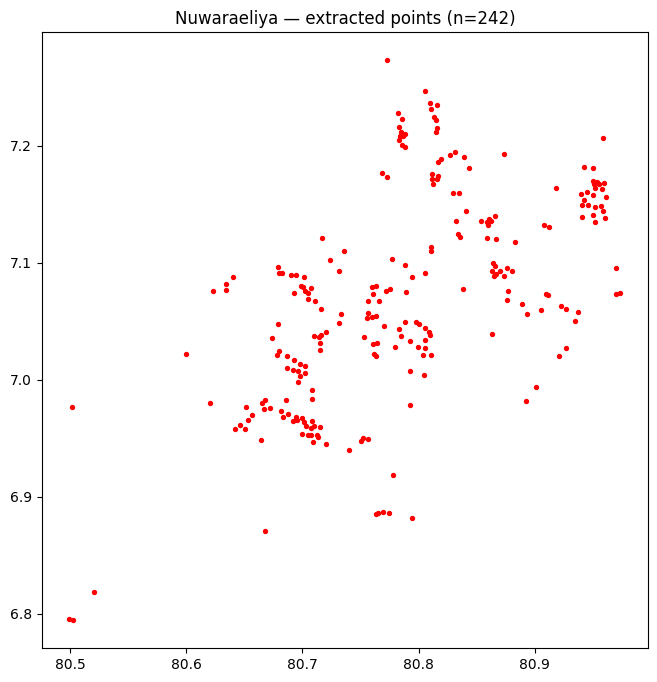

In [17]:
fig, ax = plt.subplots(figsize=(8,8))
gdf.plot(ax=ax, color="red", markersize=8)
ax.set_title(f"{MAP_NAME.capitalize()} — extracted points (n={len(gdf)})")
plt.show()


In [18]:
# ----- CHANGE PER MAP: read the total from the map's own DSD table -----
PRINTED_TOTAL = 318# e.g. from "Total: 380" row in the DSD-wise table
# -------------------------------------------------------------------------

match_pct = len(gdf) / PRINTED_TOTAL * 100
print(f"Detected: {len(gdf)} / Printed total: {PRINTED_TOTAL} ({match_pct:.1f}% match)")



Detected: 242 / Printed total: 318 (76.1% match)


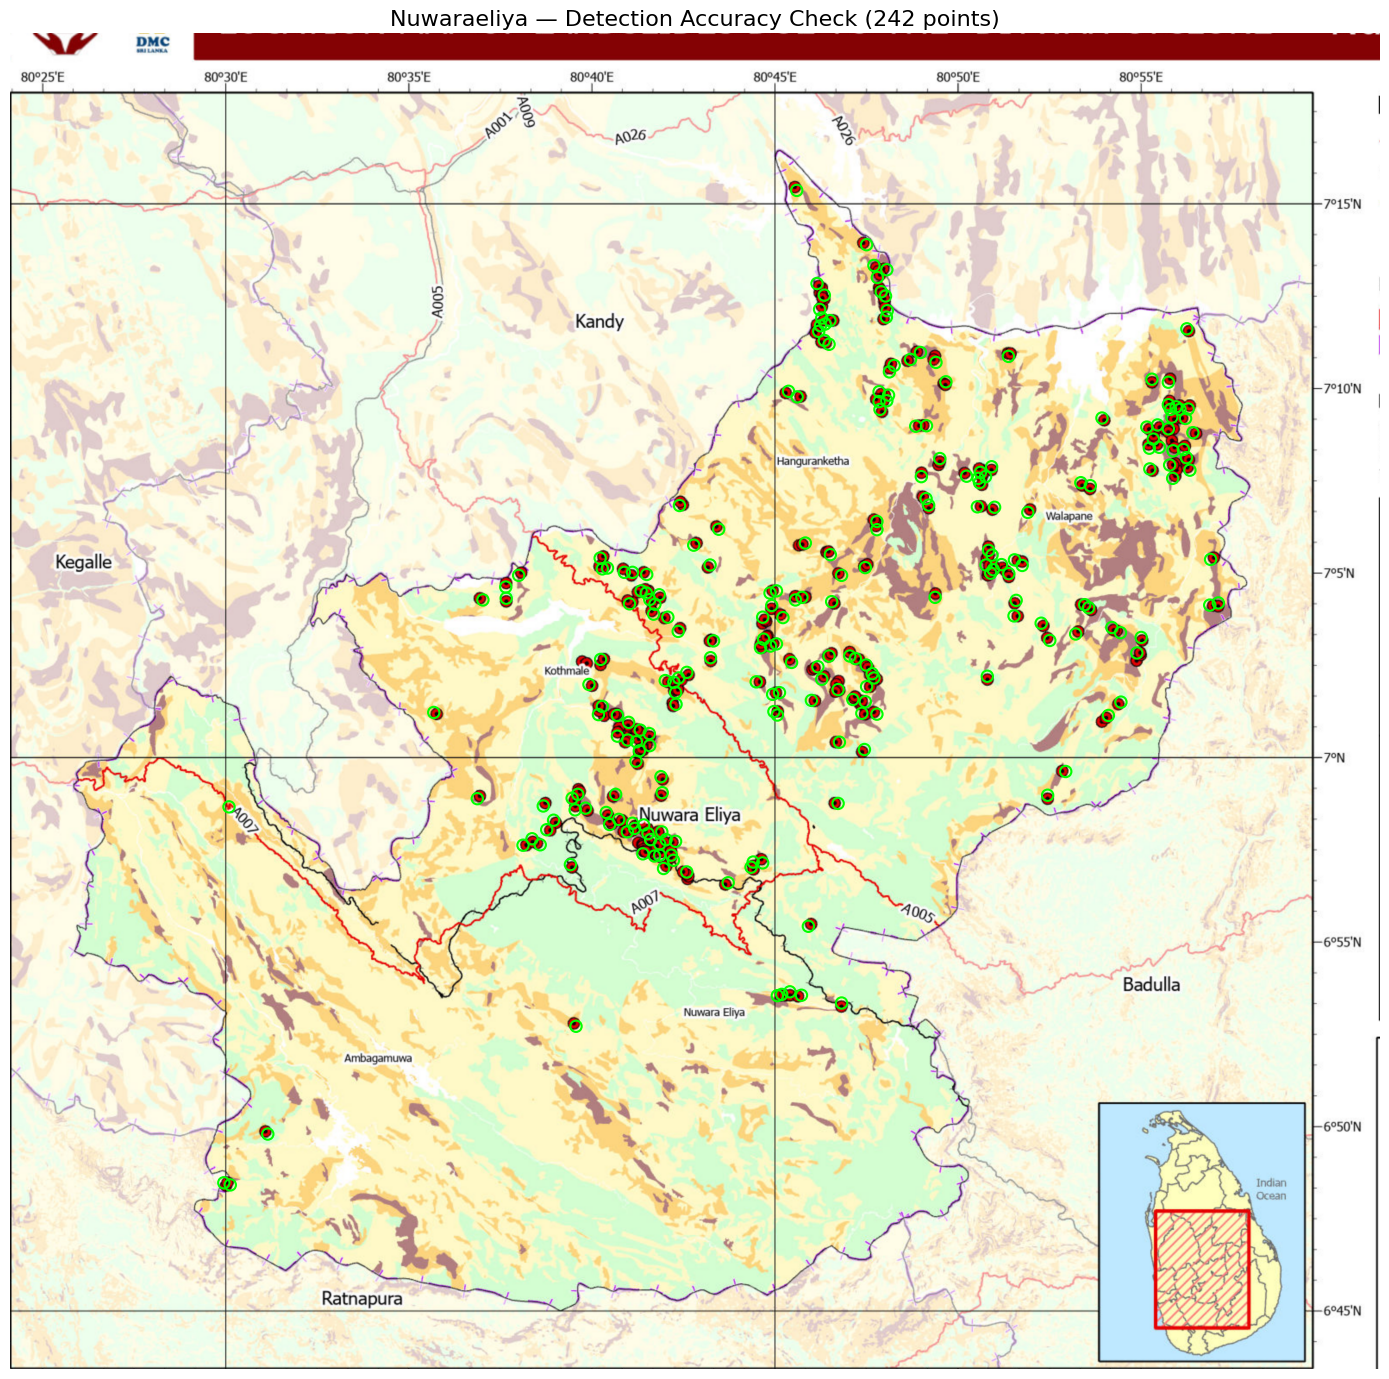

In [19]:
# Visual QA: overlay detected points on original NBRO map
# Circles are drawn in image-pixel (data) coordinates, sized to match
# the actual dot radius calibrated from SINGLE_DOT_AREA, so they scale
# correctly no matter how far you zoom in.

import numpy as np
import matplotlib.patches as mpatches
from matplotlib.collections import PatchCollection

fig, ax = plt.subplots(figsize=(14, 14))

ax.imshow(arr)

# radius (in px) of a single dot, from area = pi * r^2
dot_radius_px = np.sqrt(SINGLE_DOT_AREA / np.pi)

circles = [
    mpatches.Circle((x, y), radius=dot_radius_px * 1.3)  # slight margin so the ring is visible around the dot
    for x, y in points_px
]

ax.add_collection(
    PatchCollection(
        circles,
        facecolor="none",
        edgecolor="lime",
        linewidths=1.5
    )
)

ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(Y_MAX, Y_MIN)  # image Y axis runs downward

ax.set_title(
    f"{MAP_NAME.capitalize()} — Detection Accuracy Check ({len(points_px)} points)",
    fontsize=16
)

ax.axis("off")
plt.tight_layout()
plt.show()


In [20]:
import pandas as pd

rows = []
for i, (px, py) in enumerate(points_px, start=1):
    lon, lat = px_to_lonlat(px, py)
    rows.append({
        "id": i,
        "longitude": lon,
        "latitude": lat,
        "area_name": MAP_NAME.capitalize(),
        "pixel_x": px,
        "pixel_y": py
    })

df = pd.DataFrame(rows)
df.to_csv(DATA_PROCESSED /"NuwaraEliya_landslide_points.csv", index=False)
print(f"Saved {len(df)} points to NuwaraEliya_landslide_points.csv")

Saved 242 points to NuwaraEliya_landslide_points.csv


### Part-02 Training table

In [21]:
from pathlib import Path

import geopandas as gpd
import pandas as pd
import numpy as np
import rasterio
import matplotlib.pyplot as plt

from shapely.geometry import Point

In [22]:
#  load your extracted NuwaraEliya landslide CSV

csv_path = DATA_PROCESSED / "NuwaraEliya_landslide_points.csv"

assert csv_path.exists(), f"File not found: {csv_path}"

df = pd.read_csv(csv_path)

print(f"Rows loaded: {len(df)}")
print("Columns:", df.columns.tolist())

display(df.head())

Rows loaded: 242
Columns: ['id', 'longitude', 'latitude', 'area_name', 'pixel_x', 'pixel_y']


,id,longitude,latitude,area_name,pixel_x,pixel_y
0,1,80.772633,7.273143,Nuwaraeliya,1995.0,504.0
1,2,80.805967,7.246991,Nuwaraeliya,2157.0,630.0
2,3,80.809465,7.237028,Nuwaraeliya,2174.0,678.0
3,4,80.815638,7.234953,Nuwaraeliya,2204.0,688.0
4,5,80.811111,7.231217,Nuwaraeliya,2182.0,706.0


In [23]:
#  convert CSV coordinates to GeoDataFrame

NuwaraEliya_pts=gpd.GeoDataFrame(
    df.copy(),
    geometry=gpd.points_from_xy(
        df["longitude"],
        df["latitude"]
    ),
    crs="EPSG:4326"
)

# Convert to the same UTM CRS used by the Sri Lanka rasters
NuwaraEliya_utm = NuwaraEliya_pts.to_crs("EPSG:32644")

# Landslide class
NuwaraEliya_utm["label"] = 1

print(f"{len(NuwaraEliya_utm)} landslide points loaded")
print("CRS:", NuwaraEliya_utm.crs)

display(
    NuwaraEliya_utm[
        ["id", "longitude", "latitude", "area_name", "label", "geometry"]
    ].head()
)

242 landslide points loaded
CRS: EPSG:32644


,id,longitude,latitude,area_name,label,geometry
0,1,80.772633,7.273143,Nuwaraeliya,1,POINT (474901.955 803950.351)
1,2,80.805967,7.246991,Nuwaraeliya,1,POINT (478580.257 801057.578)
2,3,80.809465,7.237028,Nuwaraeliya,1,POINT (478965.942 799956.06)
3,4,80.815638,7.234953,Nuwaraeliya,1,POINT (479647.298 799726.33)
4,5,80.811111,7.231217,Nuwaraeliya,1,POINT (479147.395 799313.527)


In [24]:
# check that extracted points fall inside Kandy

aoi_path = DATA_PROCESSED / "aoi.gpkg"

aoi = gpd.read_file(
    aoi_path,
    layer="districts"
)

# Select Nuwara Eliya
NuwaraEliya_boundary=aoi[
    aoi["adm2_name"].astype(str).str.strip().str.lower() == "nuwara eliya"
].copy()

assert len(NuwaraEliya_boundary) > 0, "Nuwara Eliya district not found in AOI"

# IMPORTANT: convert boundary to same CRS as landslide points
NuwaraEliya_utm = NuwaraEliya_utm.to_crs("EPSG:32644")

# Merge NuwaraEliya polygon parts
try:
    NuwaraEliya_poly=NuwaraEliya_boundary.geometry.union_all()
except AttributeError:
    NuwaraEliya_poly = NuwaraEliya_boundary.unary_union

# Check points
within_nuwaraeliya = NuwaraEliya_utm.geometry.within(NuwaraEliya_poly)

print(
    f"{within_nuwaraeliya.sum()} / {len(NuwaraEliya_utm)} "
    "points fall inside Nuwara Eliya district"
)

# Keep only valid Nuwara Eliya points
NuwaraEliya_utm = (
    NuwaraEliya_utm[within_nuwaraeliya]
    .copy()
    .reset_index(drop=True)
)

print(f"Final landslide points: {len(NuwaraEliya_utm)}")

224 / 242 points fall inside Nuwara Eliya district
Final landslide points: 224


In [25]:
# generate matching non-landslide points

BUFFER_METERS = 500
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

# Create exclusion area around known landslides
try:
    buffer_union = NuwaraEliya_utm.geometry.buffer(BUFFER_METERS).union_all()
except AttributeError:
    buffer_union = NuwaraEliya_utm.geometry.buffer(BUFFER_METERS).unary_union

# Valid negative sampling area
valid_area = NuwaraEliya_poly.difference(buffer_union)

assert not valid_area.is_empty, "No valid area available for negative sampling"

minx, miny, maxx, maxy = valid_area.bounds

n_needed = len(NuwaraEliya_utm)

negatives = []
attempts = 0
max_attempts = max(10000, n_needed * 1000)

while len(negatives) < n_needed and attempts < max_attempts:

    pt = Point(
        rng.uniform(minx, maxx),
        rng.uniform(miny, maxy)
    )

    if valid_area.contains(pt):
        negatives.append(pt)

    attempts += 1


neg_gdf = gpd.GeoDataFrame(
    {
        "label": [0] * len(negatives)
    },
    geometry=negatives,
    crs="EPSG:32644"
)

print(f"Landslide points:     {len(NuwaraEliya_utm)}")
print(f"Non-landslide points: {len(neg_gdf)}")
print(f"Sampling attempts:    {attempts}")

Landslide points:     224
Non-landslide points: 224
Sampling attempts:    473


In [26]:
#  combine positive and negative Nuwara Eliya samples

positive_gdf = NuwaraEliya_utm[
    ["geometry", "label"]
].copy()

combined = pd.concat(
    [
        positive_gdf,
        neg_gdf[["geometry", "label"]]
    ],
    ignore_index=True
)

combined = gpd.GeoDataFrame(
    combined,
    geometry="geometry",
    crs="EPSG:32644"
)

print("Total Nuwara Eliya samples:", len(combined))

print("\nClass distribution:")
print(combined["label"].value_counts())

Total Nuwara Eliya samples: 448

Class distribution:
label
1    224
0    224
Name: count, dtype: int64


In [27]:
# raster sampling helper

def sample_raster_at_points(raster_path, points_gdf, band=1):

    with rasterio.open(raster_path) as src:

        pts = points_gdf.to_crs(src.crs)

        coords = [
            (geom.x, geom.y)
            for geom in pts.geometry
        ]

        values = np.array(
            [v[band - 1] for v in src.sample(coords)],
            dtype="float64"
        )

        # Convert NoData to NaN
        if src.nodata is not None:
            values[values == src.nodata] = np.nan

        return values

In [28]:
#sample existing Sri Lanka terrain rasters

raster_map = {
    "slope": "slope.tif",
    "aspect": "aspect.tif",
    "twi": "twi.tif",
    "spi": "spi.tif",
    "dist_to_river": "dist_to_river.tif",
    "dist_to_road": "dist_to_road.tif",
    "elev": "dem_utm.tif",
    "plan_curv": "plan_curvature.tif",
    "profile_curv": "profile_curvature.tif",
}

available_features = []

for name, fname in raster_map.items():

    path = DATA_PROCESSED / fname

    if path.exists():

        combined[name] = sample_raster_at_points(
            path,
            combined
        )

        available_features.append(name)

        print(f"{name}: sampled")

    else:
        print(f"{name}: MISSING — {fname}")

slope: sampled
aspect: sampled
twi: sampled
spi: sampled
dist_to_river: sampled
dist_to_road: sampled
elev: sampled
plan_curv: sampled
profile_curv: sampled


In [29]:
# metadata and cleaning

combined["country"] = "Sri Lanka"
combined["source_dataset"] = "NBRO_NuwaraEliya_MapExtraction"
combined["district"] = "Nuwara Eliya"

# Replace infinite terrain values
combined[available_features] = combined[
    available_features
].replace(
    [np.inf, -np.inf],
    np.nan
)

print("Missing raster values:")
print(combined[available_features].isna().sum())

combined_clean = combined.dropna(
    subset=available_features
).copy()

print(
    f"\nClean Nuwara Eliya rows: "
    f"{len(combined_clean)} / {len(combined)}"
)

Missing raster values:
slope            0
aspect           0
twi              0
spi              0
dist_to_river    0
dist_to_road     0
elev             0
plan_curv        0
profile_curv     0
dtype: int64

Clean Nuwara Eliya rows: 448 / 448


In [30]:
# ============================================================
# NUWARA ELIYA ONLY — FINAL TRAINING TABLE
# No COOLR data
# ============================================================

shared_cols = [
    "geometry",
    "label",
    "country",
    "source_dataset",
    "district",
] + available_features


# Keep only Nuwara Eliya data
nuwaraeliya_all = combined_clean[
    shared_cols
].copy()


# Ensure GeoDataFrame
nuwaraeliya_all = gpd.GeoDataFrame(
    nuwaraeliya_all,
    geometry="geometry",
    crs="EPSG:32644"
)


print(
    f"Total Nuwara Eliya samples: "
    f"{len(nuwaraeliya_all)}"
)

display(
    nuwaraeliya_all
    .groupby(["source_dataset", "label"])
    .size()
    .unstack(fill_value=0)
)

Total Nuwara Eliya samples: 448


label,0,1
source_dataset,,
NBRO_NuwaraEliya_MapExtraction,224,224


In [31]:
# ============================================================
# SAVE NUWARA ELIYA PARQUET
# ============================================================

parquet_path = (
    DATA_PROCESSED /
    "training_table_nuwara_eliya.parquet"
)

nuwaraeliya_all.to_parquet(
    parquet_path,
    index=False
)

print("Saved:", parquet_path)

Saved: ..\data\processed\training_table_nuwara_eliya.parquet


In [32]:
# ============================================================
# SAVE NUWARA ELIYA CSV
# ============================================================

csv_output = nuwaraeliya_all.copy()


# UTM coordinates — metres, EPSG:32644
csv_output["x"] = csv_output.geometry.x
csv_output["y"] = csv_output.geometry.y


# Convert to longitude / latitude
wgs84 = csv_output.to_crs(
    "EPSG:4326"
)

csv_output["longitude"] = (
    wgs84.geometry.x
)

csv_output["latitude"] = (
    wgs84.geometry.y
)


# Remove geometry object for CSV
csv_output = pd.DataFrame(
    csv_output.drop(
        columns="geometry"
    )
)


# Save
csv_out_path = (
    DATA_PROCESSED /
    "training_table_nuwara_eliya.csv"
)

csv_output.to_csv(
    csv_out_path,
    index=False
)


print("Saved:", csv_out_path)
print("Shape:", csv_output.shape)

display(csv_output.head())

Saved: ..\data\processed\training_table_nuwara_eliya.csv
Shape: (448, 17)


,label,country,source_dataset,district,slope,aspect,twi,spi,dist_to_river,dist_to_road,elev,plan_curv,profile_curv,x,y,longitude,latitude
0,1,Sri Lanka,NBRO_NuwaraEliya_MapExtraction,Nuwara Eliya,24.127604,75.446983,2.189480,1.791600,1218.664307,549.137329,736.489685,-0.003460,-0.000628,475967.100207,798993.718766,80.782304,7.228311
1,1,Sri Lanka,NBRO_NuwaraEliya_MapExtraction,Nuwara Eliya,21.696989,112.071167,1.614733,0.795775,1356.963867,0.000000,609.426941,0.005189,-0.001405,476352.971695,798374.023043,80.785802,7.222707
2,1,Sri Lanka,NBRO_NuwaraEliya_MapExtraction,Nuwara Eliya,5.442775,76.271675,2.350924,0.095281,1573.089233,0.000000,611.764099,0.000926,0.000557,476102.739103,797616.959149,80.783539,7.215858
3,1,Sri Lanka,NBRO_NuwaraEliya_MapExtraction,Nuwara Eliya,5.272316,265.641785,6.713663,7.013271,1721.536865,30.697712,623.241943,-0.005988,0.000200,476216.102831,797158.007360,80.784568,7.211707
4,1,Sri Lanka,NBRO_NuwaraEliya_MapExtraction,Nuwara Eliya,13.390609,241.324661,2.128378,0.476121,1509.191406,330.624481,696.833252,-0.001059,-0.000810,476647.648410,797020.136126,80.788477,7.210461
